In [17]:
!pip install  matplotlib --upgrade
!pip install wordcloud

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [18]:
import pandas as pd
import numpy as np
import re
import csv
import seaborn as sns
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [ ]:
# reading necessary DataFrames for Analysis
df1 = pd.read_csv('clean_tweets_df.csv')
df2 = pd.read_csv('final_df_labeled_pol_tweets.csv')
language = pd.read_csv('language.csv')

# **Deskriptive Analyse der Daten**

- Zeitraum der Datenerhebung

In [ ]:
# normalize dates (no time stamp)
df1['Datetime'] = pd.to_datetime(df1['Datetime']).dt.normalize()

In [ ]:
# show timeframe of data collection
df1['Datetime'] = pd.to_datetime(df1['Datetime'])
date_range = str(df1['Datetime'].dt.date.min()) + ' to ' +str(df1['Datetime'].dt.date.max())
date_range

'2022-12-03 to 2023-02-04'

- Größe der Stichprobe (nach preprocessing)
- Anzahl Politiker (gesamt)
- Anzahl Politiker nach Parteien

In [ ]:
# total number of tweets after preprocessing
df1['Clean Text'].value_counts().sum()

20530

In [ ]:
# number of politicians within sample
df1['Username'].nunique()

421

In [ ]:
df_pol = df1.drop_duplicates(subset=['Username'], keep='last')
df_pol['Party'].value_counts()

Grüne      91
SPD        89
CDU/CSU    83
FDP        79
AfD        49
Linke      30
Name: Party, dtype: int64

- Anzahl der Nutzererwähnungen am Anfang eines Tweets
- Anzahl an Nutzererwähnungen gesamt
- Anzahl an einmaligen Nutzererwähnungen 
- Die 10 meist erwähnten Nuztzer

In [ ]:
# count messages that are directed towards a certain user or multiple user 
# by checking if each string in a cell of the df1['Text'] column starts with an @-sign
df1['Text'].str.startswith('@', na=False).sum()

5434

In [ ]:
# number of total user mentions (qmentions) within sample
user_mentions_to_list = df1['Text'].values.tolist()
user_mentions_to_string = ' '.join(user_mentions_to_list)
user_mentions = re.findall(r'@[\w]+', user_mentions_to_string)
total_number_of_user_mentions = len(user_mentions)
total_number_of_user_mentions

18342

In [ ]:
# number of unique user mentions (@mentions) within sample
counter_object = Counter(user_mentions)
keys = counter_object.keys()
unique_user_mentions = len(keys)
unique_user_mentions

5501

In [ ]:
# top 10 most used user mentions
mentions = Counter(user_mentions)
mentions.most_common(10)

[('@cducsubt', 452),
 ('@fdp', 305),
 ('@spdbt', 286),
 ('@c_lindner', 199),
 ('@Bundeskanzler', 195),
 ('@fdpbt', 180),
 ('@welt', 151),
 ('@OlafScholz', 143),
 ('@CDU', 132),
 ('@GrueneBundestag', 129)]

- Anzahl an Hashtags gesamt
- Anzahl an einmaligen Hashtags
- Die 10 meist genutzen Hashtags

In [ ]:
# number of total hashtags within sample 
hashtags_to_list = df1['Text'].values.tolist()
hashtags_to_string = ' '.join(hashtags_to_list)
hashtags = re.findall(r'#[\w]+', hashtags_to_string)
total_number_of_hashtags = len(hashtags)
total_number_of_hashtags

24488

In [ ]:
# number of unique hashtags withi sample
counter_object = Counter(hashtags)
keys = counter_object.keys()
unique_hashtags = len(keys)
unique_hashtags

6736

In [ ]:
# top 10 most used hashtags
hash = Counter(hashtags)
hash.most_common(10)

[('#Ukraine', 518),
 ('#AfD', 483),
 ('#Bundestag', 385),
 ('#Berlin', 294),
 ('#Ampel', 241),
 ('#Iran', 230),
 ('#Deutschland', 216),
 ('#3K23', 166),
 ('#DieZukunftGlaubtAnUns', 153),
 ('#Luetzerath', 152)]

- Anzahl an URLs 

In [ ]:
# number of urls within sample
urls_to_list = df1['Text'].values.tolist()
urls_to_string = ' '.join(urls_to_list)
urls = re.findall(r"(?i)\b((?:https?://|www\d{0,3}[.]|[a-z0-9.\-]+[.][a-z]{2,4}/)(?:[^\s()<>]+|\(([^\s()<>]+|(\([^\s()<>]+\)))*\))+(?:\(([^\s()<>]+|(\([^\s()<>]+\)))*\)|[^\s`!()\[\]{};:'\".,<>?«»“”‘’]))", urls_to_string)
total_number_of_urls = len(urls)
total_number_of_urls

9094

- Durchschnittliche Anzahl von Wörtern in Tweets
- Tweet mit den meisten Wörtern
- Tweet mit den wenigsten Wörtern
- Durchschnittliche Tweets pro Tag
- Aufkommen verschiedener Sprachen

In [ ]:
# average number of words in a tweet
df1['Tweet Word Count'].mean()

27.337359961032636

In [ ]:
# tweet(s) with the most words
df1['Tweet Word Count'].max()

53

In [ ]:
# tweet(s) with the least amount of words
df1['Tweet Word Count'].min()

7

In [ ]:
df1['Tweet Word Count'].value_counts().head(5)

35    898
36    892
37    891
33    858
34    846
Name: Tweet Word Count, dtype: int64

In [ ]:
# average tweets posted within one day 
tweets_per_day = df1[['Clean Text']].groupby(df1['Datetime'].dt.date).count()
tweets_per_day['Clean Text'].mean()

320.78125

In [ ]:
# show different languages nefore preprocessing
language['Language'].value_counts()

Language.GERMAN     20530
Language.ENGLISH     1451
Language.FRENCH        22
Language.DUTCH          8
Name: Language, dtype: int64

- Anzahl der Label 0 und 1

In [ ]:
# occurencees of label 0 and label 1 within sample
df2['Predicted Label'].value_counts()

0    102972
1     20208
Name: Predicted Label, dtype: int64

- Mittelwert, Maximum, Minimum Sentiment Scores (Party Alignment Scores)
- Tweet mit dem höchsten Score
- Tweet mit dem niedrigsten Score

In [ ]:
# descriptive data of sentiment score (including positive and negative scores overall parties)
df2['Score of Predicted Label'].describe()

count    123180.000000
mean          0.908188
std           0.135923
min           0.500011
25%           0.862918
50%           0.985732
75%           0.998585
max           0.999475
Name: Score of Predicted Label, dtype: float64

In [ ]:
# descriptive data of sentiment score for label 0 overall parties
df2 = pd.read_csv('final_df_labeled_pol_tweets.csv')
df_label_0 = df2.loc[df2["Predicted Label"] == 0]
df_label_0['Score of Predicted Label'].describe()

count    102972.000000
mean          0.929982
std           0.119323
min           0.500011
25%           0.919447
50%           0.993075
75%           0.998908
max           0.999475
Name: Score of Predicted Label, dtype: float64

In [ ]:
# descriptive data of sentiment score for label 1 overall parties
df2 = pd.read_csv('final_df_labeled_pol_tweets.csv')
df_label_1 = df2.loc[df2["Predicted Label"] == 1]
df_label_1['Score of Predicted Label'].describe()

count    20208.000000
mean         0.797133
std          0.159098
min          0.500036
25%          0.655854
50%          0.821443
75%          0.950961
max          0.999133
Name: Score of Predicted Label, dtype: float64

In [ ]:
# tweet with the highest score 
df2[df2['Score of Predicted Label'] == df2['Score of Predicted Label'].max()]

,Unnamed: 0,Username,Name,Clean Name,Party,Text,Clean Text,Predicted Label,Score of Predicted Label,Sentiment of Predicted Label,Tweet Word Count,Tweet Id,Datetime,Url,Language
5389,5389,El_KaWeh_,Kaweh Mansoori,Kaweh Mansoori,SPD,Für die vorbehaltlose Umsetzung der #IstanbulK...,spd: Für die vorbehaltlose Umsetzung der Istan...,0,0.999475,positive,32,1620787998609801216,2023-02-01 14:15:46,https://twitter.com/El_KaWeh_/status/162078799...,Language.GERMAN


In [ ]:
# tweet with the lowest score
df2[df2['Score of Predicted Label'] == df2['Score of Predicted Label'].min()]

,Unnamed: 0,Username,Name,Clean Name,Party,Text,Clean Text,Predicted Label,Score of Predicted Label,Sentiment of Predicted Label,Tweet Word Count,Tweet Id,Datetime,Url,Language
114573,114573,SaraNanni,Sara Nanni,Sara Nanni,Grüne,@Simca1942 Stoppen kann man viel. Aber wieviel...,die linke: Stoppen kann man viel. Aber wievie...,0,0.500011,positive,44,1600541923722264576,2022-12-07 17:25:05,https://twitter.com/SaraNanni/status/160054192...,Language.GERMAN


- Ranking von Politikern anhand ihrer veröffentlichten Tweets
- Ranking der Parteien anhand ihrer veröffentlichten Tweets

In [ ]:
# top 10 ranking of politicians that tweet the most
df1['Clean Name'].value_counts(ascending=False).head(10)

Marcus Faber           549
Matthias Hauer         478
Oliver Luksic          393
 Stephan Brandner      372
Bernhard Herrmann      349
Sara Nanni             249
Martin Reichardt       241
Anke Domscheit-Berg    232
Johannes Wagner        217
Ralf Stegner           200
Name: Clean Name, dtype: int64

In [ ]:
# top 10 ranking of politicians that tweet the least
df1['Clean Name'].value_counts(ascending=True).head(12)

Rasha Nasr              1
Dr. Karamba Diaby       1
Mechthild Heil          1
Christian Sauter        1
Dr. Andreas Philippi    1
Fabian Funke            1
Heike Brehmer           1
Thomas Heilmann         1
Kathrin Michel          1
Alexander Hoffmann      1
Johannes Schraps        1
Leif-Erik Holm          1
Name: Clean Name, dtype: int64

In [ ]:
# total tweets by party
df1['Party'].value_counts()

Grüne      5204
FDP        4331
CDU/CSU    3360
SPD        2994
AfD        2600
Linke      2041
Name: Party, dtype: int64

# Diagramme zur Analyse der Daten
Erstellung von Dataframes für jede Partei anhand des Textlabels.
Es wird für jede Partei ein eigener DataFrame erstellt der nur die Tweets mit dem Parteilabel und dem dazugehörigen Score beinhaltet. Die verschiedenen Parteien werden zu der Partei des DataFrames der für eine spezifische Partei erstellt wurde umgewandelt. 

Alle Dataframes für die jeweiligen Parteien werden später zu einem DataFrame zusammengeführt welcher nach Parteien und dem korrspondierend Parteilabel sortiert sind.

Dieses vorgehen ermöglicht das erstellen eines Boxplots welches die Parteien und die Scores (für Label 0 und 1) beinhaltet. Hierbei Korrespondiert die Partei mit dem Parteilabel der Tweets. Somit können für das Boxplot auf der x-Achse die Partei und auf der y-Achse der Score verwendet werden.

Bsp. anhand des cdu/csu: Parteilabels

    vorher

    Name         Partei   Tweet                  Score
    Olaf Scholz  SPD      cdu/csu: Tweet Text    0.998

    nachher 

    Name        Partei    Tweet                  Score
    Olaf Scholz CDU/CSU   cdu/csu: Tweet Text    0.998
 

In [3]:
# creating cdu/csu DataFrame containing score and labels (0/1) and party (cdu/csu only)
plot = pd.read_csv('final_df_labeled_pol_tweets.csv')
# just keeping lines that have the cdu/csu: text label
plot = plot.iloc[::6, :]
# renaming all party labels of ['Party] column to CDU/CSU
plot['Party'] = plot['Party'].str.replace('SPD', 'CDU/CSU', regex=True)
plot['Party'] = plot['Party'].str.replace('Grüne', 'CDU/CSU', regex=True)
plot['Party'] = plot['Party'].str.replace('Linke', 'CDU/CSU', regex=True)
plot['Party'] = plot['Party'].str.replace('FDP', 'CDU/CSU', regex=True)
plot['Party'] = plot['Party'].str.replace('AfD', 'CDU/CSU', regex=True)
plot.to_csv('analysis_cdu_csu.csv')

# creating spd DataFrame containing score and labels (0/1) and party (spd only)
plot = pd.read_csv('final_df_labeled_pol_tweets.csv')
# just keeping lines that have the spd: text label
plot = plot.iloc[1::6, :]
# renaming all party labels of ['Party] column to SPD
plot['Party'] = plot['Party'].str.replace('CDU/CSU', 'SPD', regex=True)
plot['Party'] = plot['Party'].str.replace('Grüne', 'SPD', regex=True)
plot['Party'] = plot['Party'].str.replace('Linke', 'SPD', regex=True)
plot['Party'] = plot['Party'].str.replace('FDP', 'SPD', regex=True)
plot['Party'] = plot['Party'].str.replace('AfD', 'SPD', regex=True)
plot.to_csv('analysis_spd.csv')

# creating grüne DataFrame containing score and labels (0/1) and party (grüne only)
plot = pd.read_csv('final_df_labeled_pol_tweets.csv')
# just keeping lines that have the grüne: text label
plot = plot.iloc[2::6, :]
# renaming all party labels of ['Party] column to Grüne
plot['Party'] = plot['Party'].str.replace('CDU/CSU', 'Grüne', regex=True)
plot['Party'] = plot['Party'].str.replace('SPD', 'Grüne', regex=True)
plot['Party'] = plot['Party'].str.replace('Linke', 'Grüne', regex=True)
plot['Party'] = plot['Party'].str.replace('FDP', 'Grüne', regex=True)
plot['Party'] = plot['Party'].str.replace('AfD', 'Grüne', regex=True)
plot.to_csv('analysis_grüne.csv')

# creating die linke DataFrame containing score and labels (0/1) and party (die linke only)
plot = pd.read_csv('final_df_labeled_pol_tweets.csv')
# just keeping lines that have the die linke: text label
plot = plot.iloc[3::6, :]
plot.to_csv('analysis_die_linke.csv')
analysis_die_linke = pd.read_csv('analysis_die_linke.csv')
# renaming all party labels of ['Party] column to Linke
analysis_die_linke['Party'] = analysis_die_linke['Party'].str.replace('CDU/CSU', 'Linke', regex=True)
analysis_die_linke['Party'] = analysis_die_linke['Party'].str.replace('SPD', 'Linke', regex=True)
analysis_die_linke['Party'] = analysis_die_linke['Party'].str.replace('Grüne', 'Linke', regex=True)
analysis_die_linke['Party'] = analysis_die_linke['Party'].str.replace('FDP', 'Linke', regex=True)
analysis_die_linke['Party'] = analysis_die_linke['Party'].str.replace('AfD', 'Linke', regex=True)
analysis_die_linke.to_csv('analysis_die_linke.csv')

# creating fdp DataFrame containing score and labels (0/1) and party (fdp only)
plot = pd.read_csv('final_df_labeled_pol_tweets.csv')
# just keeping lines that have the fdp: text label
plot = plot.iloc[4::6, :]
# renaming all party labels of ['Party] column to FDP
plot['Party'] = plot['Party'].str.replace('CDU/CSU', 'FDP', regex=True)
plot['Party'] = plot['Party'].str.replace('SPD', 'FDP', regex=True)
plot['Party'] = plot['Party'].str.replace('Grüne', 'FDP', regex=True)
plot['Party'] = plot['Party'].str.replace('Linke', 'FDP', regex=True)
plot['Party'] = plot['Party'].str.replace('AfD', 'FDP', regex=True)
plot.to_csv('analysis_fdp.csv')

# creating afd DataFrame containing score and labels (0/1) and party (fafd only)
plot = pd.read_csv('final_df_labeled_pol_tweets.csv')
# just keeping lines that have the fafd: text label
plot = plot.iloc[5::6, :]
plot.to_csv('analysis_afd.csv')
analysis_afd = pd.read_csv('analysis_afd.csv')
# renaming all party labels of ['Party] column to AfD
analysis_afd['Party'] = analysis_afd['Party'].str.replace('CDU/CSU', 'AfD', regex=True)
analysis_afd['Party'] = analysis_afd['Party'].str.replace('SPD', 'AfD', regex=True)
analysis_afd['Party'] = analysis_afd['Party'].str.replace('Grüne', 'AfD', regex=True)
analysis_afd['Party'] = analysis_afd['Party'].str.replace('Linke', 'AfD', regex=True)
analysis_afd['Party'] = analysis_afd['Party'].str.replace('FDP', 'AfD', regex=True)
analysis_afd.to_csv('analysis_afd.csv')

# Boxplot 
- Scores aller Parteien für Label 0/1


(array([0, 1, 2, 3, 4, 5]),
 [Text(0, 0, 'CDU/CSU'),
  Text(1, 0, 'SPD'),
  Text(2, 0, 'Grüne'),
  Text(3, 0, 'Linke'),
  Text(4, 0, 'FDP'),
  Text(5, 0, 'AfD')])

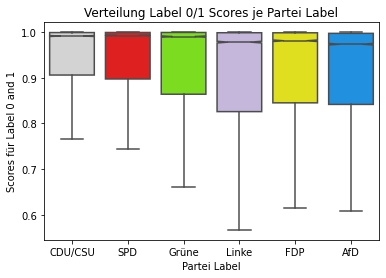

In [14]:
# combining DataFrames the DataFrame will be sorted by party and partylabel
cdu_csu = pd.read_csv('analysis_cdu_csu.csv')
spd = pd.read_csv('analysis_spd.csv')
grüne = pd.read_csv('analysis_grüne.csv')
linke = pd.read_csv('analysis_die_linke.csv')
fdp = pd.read_csv('analysis_fdp.csv')
afd = pd.read_csv('analysis_afd.csv')

plot_df = pd.concat([cdu_csu, spd, grüne, linke, fdp, afd], ignore_index=True)

# create seaborn boxplot by party and score by label 0/1
party_col = {'CDU/CSU' : '#D3D3D3', 'SPD' : '#FF0000', 'Grüne' : '#7CFC00', 'Linke' : '#C3B1E1','FDP' : '#FFFF00','AfD' : '#0096FF'}
sns.boxplot(x='Party', y='Score of Predicted Label', palette=party_col, notch = True,
            data=plot_df, showfliers=False).set(title='Verteilung Label 0/1 Scores je Partei Label')

# modify axis labels
plt.xlabel('Partei Label')
plt.ylabel('Scores für Label 0 and 1')
plt.xticks(rotation=0)

<AxesSubplot:xlabel='Score of Predicted Label', ylabel='Count'>

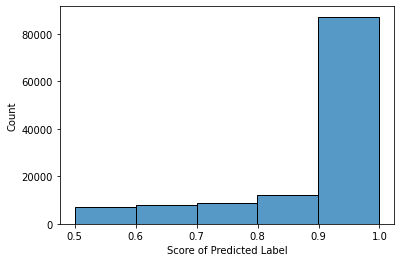

In [8]:
# histogram of score distribution of label 0/1
score = plot_df
sns.histplot(data=score, x="Score of Predicted Label", bins=5)

# Boxplot 
- Scores aller Parteien nur Label 0

In [9]:
# creating separate DataFrames by label for cdu/csu
# label 0
analysis_cdu_csu = pd.read_csv('analysis_cdu_csu.csv')
analysis_cdu_csu.drop(analysis_cdu_csu[analysis_cdu_csu['Predicted Label'] == 1].index, inplace=True)
analysis_cdu_csu.to_csv('analysis_cdu_csu_0.csv')
# label 1
analysis_cdu_csu = pd.read_csv('analysis_cdu_csu.csv')
analysis_cdu_csu.drop(analysis_cdu_csu[analysis_cdu_csu['Predicted Label'] == 0].index, inplace=True)
analysis_cdu_csu.to_csv('analysis_cdu_csu_1.csv')

# creating sepaeate DataFrames by label for spd
# label 0
analysis_spd = pd.read_csv('analysis_spd.csv')
analysis_spd.drop(analysis_spd[analysis_spd['Predicted Label'] == 1].index, inplace=True)
analysis_spd.to_csv('analysis_spd_0.csv')
# label 1
analysis_spd = pd.read_csv('analysis_spd.csv')
analysis_spd.drop(analysis_spd[analysis_spd['Predicted Label'] == 0].index, inplace=True)
analysis_spd.to_csv('analysis_spd_1.csv')

# creating sepaeate DataFrames by label for grüne
#label 0
analysis_grüne = pd.read_csv('analysis_grüne.csv')
analysis_grüne.drop(analysis_grüne[analysis_grüne['Predicted Label'] == 1].index, inplace=True)
analysis_grüne.to_csv('analysis_grüne_0.csv')
#label 1
analysis_grüne = pd.read_csv('analysis_grüne.csv')
analysis_grüne.drop(analysis_grüne[analysis_grüne['Predicted Label'] == 0].index, inplace=True)
analysis_grüne.to_csv('analysis_grüne_1.csv')

# creating sepaeate DataFrames by label for die linke
# label 0
analysis_die_linke = pd.read_csv('analysis_die_linke.csv')
analysis_die_linke.drop(analysis_die_linke[analysis_die_linke['Predicted Label'] == 1].index, inplace=True)
analysis_die_linke.to_csv('analysis_die_linke_0.csv')
# label 1
analysis_die_linke = pd.read_csv('analysis_die_linke.csv')
analysis_die_linke.drop(analysis_die_linke[analysis_die_linke['Predicted Label'] == 0].index, inplace=True)
analysis_die_linke.to_csv('analysis_die_linke_1.csv')

# creating sepaeate DataFrames by label for fdp
# label 0
analysis_fdp = pd.read_csv('analysis_fdp.csv')
analysis_fdp.drop(analysis_fdp[analysis_fdp['Predicted Label'] == 1].index, inplace=True)
analysis_fdp.to_csv('analysis_fdp_0.csv')
# label 1
analysis_fdp = pd.read_csv('analysis_fdp.csv')
analysis_fdp.drop(analysis_fdp[analysis_fdp['Predicted Label'] == 0].index, inplace=True)
analysis_fdp.to_csv('analysis_fdp_1.csv')

# creating sepaeate DataFrames by label for afd
# label 0
analysis_afd = pd.read_csv('analysis_afd.csv')
analysis_afd.drop(analysis_afd[analysis_afd['Predicted Label'] == 1].index, inplace=True)
analysis_afd.to_csv('analysis_afd_0.csv')
# label 1
analysis_afd = pd.read_csv('analysis_afd.csv')
analysis_afd.drop(analysis_afd[analysis_afd['Predicted Label'] == 0].index, inplace=True)
analysis_afd.to_csv('analysis_afd_1.csv')

(array([0, 1, 2, 3, 4, 5]),
 [Text(0, 0, 'CDU/CSU'),
  Text(1, 0, 'SPD'),
  Text(2, 0, 'Grüne'),
  Text(3, 0, 'Linke'),
  Text(4, 0, 'FDP'),
  Text(5, 0, 'AfD')])

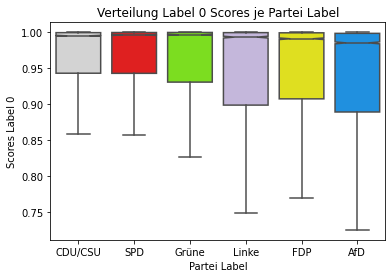

In [15]:
# reading party DataFrames by label 0
cdu_csu_0 = pd.read_csv('analysis_cdu_csu_0.csv')
spd_0 = pd.read_csv('analysis_spd_0.csv')
grüne_0 = pd.read_csv('analysis_grüne_0.csv')
die_linke_0 = pd.read_csv('analysis_die_linke_0.csv')
fdp_0 = pd.read_csv('analysis_fdp_0.csv')
afd_0 = pd.read_csv('analysis_afd_0.csv')

# combining DataFrames the DataFrame will be sorted by party and partylabel
plot_df_0 = pd.concat([cdu_csu_0, spd_0, grüne_0, die_linke_0, fdp_0, afd_0], ignore_index=True)

# create seaborn boxplot by party and score for label 0
party_col = {'CDU/CSU' : '#D3D3D3', 'SPD' : '#FF0000', 'Grüne' : '#7CFC00', 'Linke' : '#C3B1E1','FDP' : '#FFFF00','AfD' : '#0096FF'}
sns.boxplot(x='Party', y='Score of Predicted Label', palette=party_col, notch = True,
            data=plot_df_0, showfliers=False).set(title='Verteilung Label 0 Scores je Partei Label')

# modify axis labels
plt.xlabel('Partei Label')
plt.ylabel('Scores Label 0')
plt.xticks(rotation=0)

<AxesSubplot:xlabel='Score of Predicted Label', ylabel='Count'>

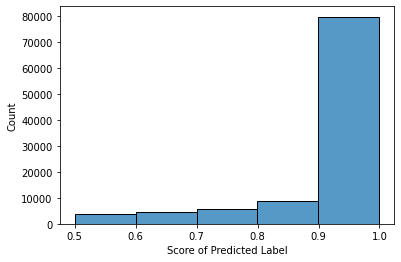

In [11]:
# histogram of score distribution of label 0
score_0 = plot_df_0
sns.histplot(data=score_0, x="Score of Predicted Label", bins=5)

# Boxplot 
- Scores aller Parteien nur Label 1

(array([0, 1, 2, 3, 4, 5]),
 [Text(0, 0, 'CDU/CSU'),
  Text(1, 0, 'SPD'),
  Text(2, 0, 'Grüne'),
  Text(3, 0, 'Linke'),
  Text(4, 0, 'FDP'),
  Text(5, 0, 'AfD')])

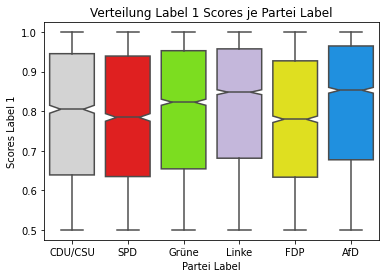

In [16]:
# reading party DataFrames by label 1
cdu_csu_1 = pd.read_csv('analysis_cdu_csu_1.csv')
spd_1 = pd.read_csv('analysis_spd_1.csv')
grüne_1 = pd.read_csv('analysis_grüne_1.csv')
die_linke_1 = pd.read_csv('analysis_die_linke_1.csv')
fdp_1 = pd.read_csv('analysis_fdp_1.csv')
afd_1 = pd.read_csv('analysis_afd_1.csv')

# combining DataFrames the DataFrame will be sorted by party and partylabel
plot_df_1 = pd.concat([cdu_csu_1, spd_1, grüne_1, die_linke_1, fdp_1, afd_1], ignore_index=True)

# create seaborn boxplot by party and score for label 1
party_col = {'CDU/CSU' : '#D3D3D3', 'SPD' : '#FF0000', 'Grüne' : '#7CFC00', 'Linke' : '#C3B1E1','FDP' : '#FFFF00','AfD' : '#0096FF'}
sns.boxplot(x='Party', y='Score of Predicted Label', palette=party_col, notch = True,
            data=plot_df_1, showfliers=False).set(title='Verteilung Label 1 Scores je Partei Label')
# modify axis labels
plt.xlabel('Partei Label')
plt.ylabel('Scores Label 1')
plt.xticks(rotation=0)

<AxesSubplot:xlabel='Score of Predicted Label', ylabel='Count'>

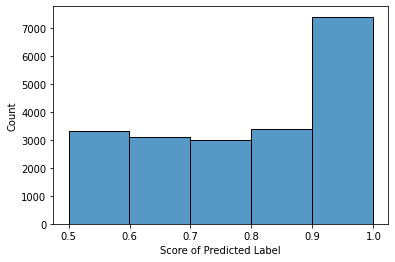

In [13]:
# histogram of score distribution of label 1
score_1 = plot_df_1
sns.histplot(data=score_1, x="Score of Predicted Label", bins=5)

# **Modell Performance**
- Kreieren eines Holdout-Sets 
- Confusion Matrix
- Classification Report

In [ ]:
# creating a new column based on conditions which serves as "true label"  and will be used as a holdout set
# if a tweet is from a particular party the tweet gets labeled with 0 otherwise it gets labeld with 1
# example Olaf Scholz --> spd: Rente soll 2023 erhöht werden.
# the true labels for this particualr example should look like this...

# cdu/csu: label 1
# spd: label 0
# grüne: label 1
# die linke: label 1
# fdp: label 1
# afd: label 1

model_performance = pd.read_csv('final_df_labeled_pol_tweets.csv')

conditions = [
     (model_performance['Party'].eq('CDU/CSU')) & (model_performance['Clean Text'].str.startswith(r'cdu/csu:')),
     (model_performance['Party'].eq('SPD')) & (model_performance['Clean Text'].str.startswith(r'spd:')),
     (model_performance['Party'].eq('Grüne')) & (model_performance['Clean Text'].str.startswith(r'grüne:')),
     (model_performance['Party'].eq('Linke')) & (model_performance['Clean Text'].str.startswith(r'die linke:')),
     (model_performance['Party'].eq('FDP')) & (model_performance['Clean Text'].str.startswith(r'fdp:')),
     (model_performance['Party'].eq('AfD')) & (model_performance['Clean Text'].str.startswith(r'afd:'))]

choices = [0,0,0,0,0,0]

model_performance['True Label'] = np.select(conditions, choices, default=1)

model_performance = model_performance[['Name', 'Clean Name', 'Party','Text', 'Clean Text', 'Predicted Label', 'True Label', 'Score of Predicted Label', 'Sentiment of Predicted Label','Tweet Word Count', 'Username', 'Tweet Id', 'Datetime', 'Url', 'Language']]

In [ ]:
model_performance['Predicted Label'].value_counts()

0    102972
1     20208
Name: Predicted Label, dtype: int64

In [ ]:
model_performance['True Label'].value_counts()

1    102650
0     20530
Name: True Label, dtype: int64

In [ ]:
# confusion matrix based on predicted and true labels
from sklearn.metrics import confusion_matrix
y_true = model_performance['True Label']
y_pred = model_performance['Predicted Label']
confusion_matrix(y_true, y_pred)

array([[17564,  2966],
       [85408, 17242]])

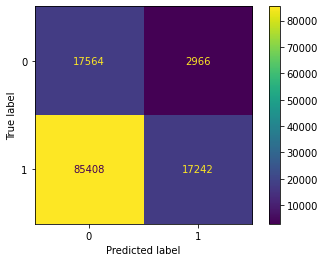

In [ ]:
# confusion matrix based on predicted and true labels displayed in a 4x4 Matrix
from sklearn.metrics import ConfusionMatrixDisplay
#from sklearn.metrics._plot.confusion_matrix import plo

x_labels = ["False Positive", "False Negative"]
y_labels = ["True Positive", "True Negative"]

y_pred = model_performance['Predicted Label']
cm = confusion_matrix(y_true, y_pred)

cm_display = ConfusionMatrixDisplay(cm).plot()

In [ ]:
# classification report of the model
from sklearn.metrics import classification_report

y_true = model_performance['True Label']
y_pred = model_performance['Predicted Label']
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.17      0.86      0.28     20530
           1       0.85      0.17      0.28    102650

    accuracy                           0.28    123180
   macro avg       0.51      0.51      0.28    123180
weighted avg       0.74      0.28      0.28    123180



# Analyse der Tweets 
- Balkendiagramme je Partei und Label 0 Klassifikation
- Wordclouds je Partei um Ähnlichkeiten in der Wortwahl zu bestimmen

Erstellung von DataFrames je Partei. Die DataFrames sind so aufgebaut das sie jeweils nur die Politiker der Partei der sie angehören beinhalten sowie deren Tweets welche die Label 0 Klassifizierung erhalten haben. Das Label 1 wird nicht berücksichtigt. Für alle vorhandenen Label 0 werden extra Spalten erstellt welche alle Parteien beinhalten d.h. wenn ein Tweet mit 0 klassifiziert wurde, wird eine 1 in die dementsprechende Spalte als ein "Zähler" eingetragen. Alle Spalten die eine 1 beinhalten werden für die jeweilige Partei aufsummiert danach findet die Zerlegung in einen DataFrame für jede Partei statt. Nun wird für jede Partei ein Balken Diagramm erstellt. Dies soll veranschaulichen inwiefern sich Parteien in ihrem Tweet Verhalten bezogen auf Twwet Inhalte ähneln bzw. nicht ähneln.


In [ ]:
cdu_csu = pd.read_csv('final_df_labeled_pol_tweets.csv')
cdu_csu = cdu_csu.loc[cdu_csu['Party'] == 'CDU/CSU']
cdu_csu = cdu_csu.loc[cdu_csu['Predicted Label'] == 0]

# creating conditions: the party has to be CDU/CSU and contain one of the 6 textlabel as well as the label 0, if these conditions are met
# a new column with the corresponding party according to the textlabel will be created and given the value of 1
# the values of the new columns will be added up for each party of the column s and displayed in a bar chart

# condition 1
conditions = [
     (cdu_csu['Party'].eq('CDU/CSU')) & (cdu_csu['Clean Text'].str.startswith(r'cdu/csu:')) & (cdu_csu['Predicted Label'].eq(0))]

choices = [1]

cdu_csu['CDU/CSU'] = np.select(conditions, choices, default=0)

# creating new column based on condition
cdu_csu = cdu_csu[['Party', 'Clean Text', 'Predicted Label', 'CDU/CSU']]

# condition 2
conditions = [
     (cdu_csu['Party'].eq('CDU/CSU')) & (cdu_csu['Clean Text'].str.startswith(r'spd:')) & (cdu_csu['Predicted Label'].eq(0))]

choices = [1]

cdu_csu['SPD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
cdu_csu = cdu_csu[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD']]

# condition 3
conditions = [
     (cdu_csu['Party'].eq('CDU/CSU')) & (cdu_csu['Clean Text'].str.startswith(r'grüne:')) & (cdu_csu['Predicted Label'].eq(0))]

choices = [1]

cdu_csu['Grüne'] = np.select(conditions, choices, default=0)

# creating new column based on condition
cdu_csu = cdu_csu[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne']]

# condition 4
conditions = [
     (cdu_csu['Party'].eq('CDU/CSU')) & (cdu_csu['Clean Text'].str.startswith(r'die linke:')) & (cdu_csu['Predicted Label'].eq(0))]

choices = [1]

cdu_csu['Die Linke'] = np.select(conditions, choices, default=0)

# creating new column based on condition
cdu_csu = cdu_csu[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke']]

# condition 5
conditions = [
     (cdu_csu['Party'].eq('CDU/CSU')) & (cdu_csu['Clean Text'].str.startswith(r'fdp:')) & (cdu_csu['Predicted Label'].eq(0))]

choices = [1]

cdu_csu['FDP'] = np.select(conditions, choices, default=0)

# creating new column based on condition
cdu_csu = cdu_csu[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP']]

# condition 6
conditions = [
     (cdu_csu['Party'].eq('CDU/CSU')) & (cdu_csu['Clean Text'].str.startswith(r'afd:')) & (cdu_csu['Predicted Label'].eq(0))]

choices = [1]

cdu_csu['AfD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
cdu_csu = cdu_csu[['CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP', 'AfD']]

In [ ]:
cdu_csu.shape

(16608, 6)

[Text(0, 0, '2954'),
 Text(0, 0, '2907'),
 Text(0, 0, '2716'),
 Text(0, 0, '2453'),
 Text(0, 0, '2841'),
 Text(0, 0, '2737')]

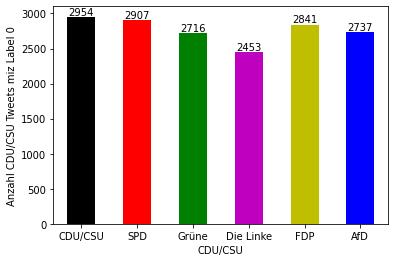

In [ ]:
# bar chart of cdu/csu label 0 klassifikation
ax = cdu_csu.sum().plot.bar(rot=0, color=('k','r', 'g', 'm', 'y','b'))
ax.set(xlabel="CDU/CSU", ylabel='Anzahl CDU/CSU Tweets miz Label 0')
ax.bar_label(ax.containers[0])

In [ ]:
spd = pd.read_csv('final_df_labeled_pol_tweets.csv')
spd = spd.loc[spd['Party'] == 'SPD']
spd = spd.loc[spd['Predicted Label'] == 0]

# creating conditions: the party has to be SPD and contain one of the 6 textlabel as well as the label 0, if these conditions are met
# a new column with the corresponding party according to the textlabel will be created and given the value of 1
# the values of the new columns will be added up for each party of the column s and displayed in a bar chart

# condition 1
conditions = [
     (spd['Party'].eq('SPD')) & (spd['Clean Text'].str.startswith(r'cdu/csu:')) & (spd['Predicted Label'].eq(0))]

choices = [1]

spd['CDU/CSU'] = np.select(conditions, choices, default=0)

# creating new column based on condition
spd = spd[['Party', 'Clean Text', 'Predicted Label', 'CDU/CSU']]

# condition 2
conditions = [
     (spd['Party'].eq('SPD')) & (spd['Clean Text'].str.startswith(r'spd:')) & (spd['Predicted Label'].eq(0))]

choices = [1]

spd['SPD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
spd = spd[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD']]

# condition 3
conditions = [
     (spd['Party'].eq('SPD')) & (spd['Clean Text'].str.startswith(r'grüne:')) & (spd['Predicted Label'].eq(0))]

choices = [1]

spd['Grüne'] = np.select(conditions, choices, default=0)

# creating new column based on condition
spd = spd[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne']]

# condition 4
conditions = [
     (spd['Party'].eq('SPD')) & (spd['Clean Text'].str.startswith(r'die linke:')) & (spd['Predicted Label'].eq(0))]

choices = [1]

spd['Die Linke'] = np.select(conditions, choices, default=0)

# creating new column based on condition
spd = spd[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke']]

# condition 5
conditions = [
     (spd['Party'].eq('SPD')) & (spd['Clean Text'].str.startswith(r'fdp:')) & (spd['Predicted Label'].eq(0))]

choices = [1]

spd['FDP'] = np.select(conditions, choices, default=0)

# creating new column based on condition
spd = spd[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP']]

# condition  6
conditions = [
     (spd['Party'].eq('SPD')) & (spd['Clean Text'].str.startswith(r'afd:')) & (spd['Predicted Label'].eq(0))]

choices = [1]

spd['AfD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
spd = spd[['CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP', 'AfD']]

<ipython-input-5-b2080cdc6df8>:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  spd['SPD'] = np.select(conditions, choices, default=0)


In [ ]:
spd.shape

(15629, 6)

[Text(0, 0, '2751'),
 Text(0, 0, '2730'),
 Text(0, 0, '2602'),
 Text(0, 0, '2455'),
 Text(0, 0, '2615'),
 Text(0, 0, '2476')]

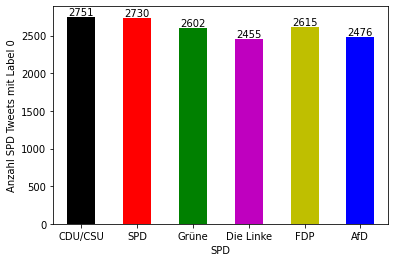

In [ ]:
# bar chart of spd label 0 klassifikation
ax = spd.sum().plot.bar(rot=0, color=('k','r', 'g', 'm', 'y','b'))
ax.set(xlabel="SPD", ylabel='Anzahl SPD Tweets mit Label 0')
ax.bar_label(ax.containers[0])

In [ ]:
grüne = pd.read_csv('final_df_labeled_pol_tweets.csv')
grüne = grüne.loc[grüne['Party'] == 'Grüne']
grüne = grüne.loc[grüne['Predicted Label'] == 0]

# creating conditions: the party has to be Grüne and contain one of the 6 textlabel as well as the label 0, if these conditions are met
# a new column with the corresponding party according to the textlabel will be created and given the value of 1
# the values of the new columns will be added up for each party of the column s and displayed in a bar chart

#condition 1
conditions = [
     (grüne['Party'].eq('Grüne')) & (grüne['Clean Text'].str.startswith(r'cdu/csu:')) & (grüne['Predicted Label'].eq(0))]

choices = [1]

grüne['CDU/CSU'] = np.select(conditions, choices, default=0)

# creating new column based on condition
grüne = grüne[['Party', 'Clean Text', 'Predicted Label', 'CDU/CSU']]

#condition 2
conditions = [
     (grüne['Party'].eq('Grüne')) & (grüne['Clean Text'].str.startswith(r'spd:')) & (grüne['Predicted Label'].eq(0))]

choices = [1]

grüne['SPD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
grüne = grüne[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD']]

#condition 3
conditions = [
     (grüne['Party'].eq('Grüne')) & (grüne['Clean Text'].str.startswith(r'grüne:')) & (grüne['Predicted Label'].eq(0))]

choices = [1]

grüne['Grüne'] = np.select(conditions, choices, default=0)

# creating new column based on condition
grüne = grüne[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne']]

#condition 4
conditions = [
     (grüne['Party'].eq('Grüne')) & (grüne['Clean Text'].str.startswith(r'die linke:')) & (grüne['Predicted Label'].eq(0))]

choices = [1]

grüne['Die Linke'] = np.select(conditions, choices, default=0)

# creating new column based on condition
grüne = grüne[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke']]

#condition 5
conditions = [
     (grüne['Party'].eq('Grüne')) & (grüne['Clean Text'].str.startswith(r'fdp:')) & (grüne['Predicted Label'].eq(0))]

choices = [1]

grüne['FDP'] = np.select(conditions, choices, default=0)

# creating new column based on condition
grüne = grüne[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP']]

#condition 6
conditions = [
     (grüne['Party'].eq('Grüne')) & (grüne['Clean Text'].str.startswith(r'afd:')) & (grüne['Predicted Label'].eq(0))]

choices = [1]

grüne['AfD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
grüne = grüne[['CDU/CSU', 'SPD',  'Grüne', 'Die Linke', 'FDP', 'AfD']]

In [ ]:
grüne.shape

(27040, 6)

[Text(0, 0, '4679'),
 Text(0, 0, '4782'),
 Text(0, 0, '4534'),
 Text(0, 0, '4386'),
 Text(0, 0, '4454'),
 Text(0, 0, '4205')]

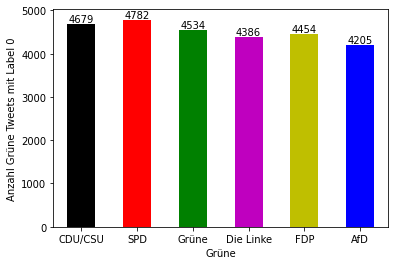

In [ ]:
# bar chart of grüne label 0 klassifikation
ax = grüne.sum().plot.bar(rot=0, color=('k','r', 'g', 'm', 'y','b'))
ax.set(xlabel="Grüne", ylabel='Anzahl Grüne Tweets mit Label 0')
ax.bar_label(ax.containers[0])

In [ ]:
die_linke = pd.read_csv('final_df_labeled_pol_tweets.csv')
die_linke = die_linke.loc[die_linke['Party'] == 'Linke']
die_linke = die_linke.loc[die_linke['Predicted Label'] == 0]

# creating conditions: the party has to be Linke and contain one of the 6 textlabel as well as the label 0, if these conditions are met
# a new column with the corresponding party according to the textlabel will be created and given the value of 1
# the values of the new columns will be added up for each party of the column s and displayed in a bar chart

#condition 1
conditions = [
     (die_linke['Party'].eq('Linke')) & (die_linke['Clean Text'].str.startswith(r'cdu/csu:')) & (die_linke['Predicted Label'].eq(0))]

choices = [1]

die_linke['CDU/CSU'] = np.select(conditions, choices, default=0)

# creating new column based on condition
die_linke = die_linke[['Party', 'Clean Text', 'Predicted Label', 'CDU/CSU']]

#condition 2
conditions = [
     (die_linke['Party'].eq('Linke')) & (die_linke['Clean Text'].str.startswith(r'spd:')) & (die_linke['Predicted Label'].eq(0))]

choices = [1]

die_linke['SPD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
die_linke = die_linke[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD']]

#condition 3
conditions = [
     (die_linke['Party'].eq('Linke')) & (die_linke['Clean Text'].str.startswith(r'grüne:')) & (die_linke['Predicted Label'].eq(0))]

choices = [1]

die_linke['Grüne'] = np.select(conditions, choices, default=0)

# creating new column based on condition
die_linke = die_linke[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne']]

#condition 4
conditions = [
     (die_linke['Party'].eq('Linke')) & (die_linke['Clean Text'].str.startswith(r'die linke:')) & (die_linke['Predicted Label'].eq(0))]

choices = [1]

die_linke['Die Linke'] = np.select(conditions, choices, default=0)

# creating new column based on condition
die_linke = die_linke[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke']]

#condition 5
conditions = [
     (die_linke['Party'].eq('Linke')) & (die_linke['Clean Text'].str.startswith(r'fdp:')) & (die_linke['Predicted Label'].eq(0))]

choices = [1]

die_linke['FDP'] = np.select(conditions, choices, default=0)

# creating new column based on condition
die_linke = die_linke[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP']]

#condition 6
conditions = [
     (die_linke['Party'].eq('Linke')) & (die_linke['Clean Text'].str.startswith(r'afd:')) & (die_linke['Predicted Label'].eq(0))]

choices = [1]

die_linke['AfD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
die_linke = die_linke[['CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP', 'AfD']]

In [ ]:
die_linke.shape

(10348, 6)

[Text(0, 0, '1823'),
 Text(0, 0, '1829'),
 Text(0, 0, '1698'),
 Text(0, 0, '1577'),
 Text(0, 0, '1735'),
 Text(0, 0, '1686')]

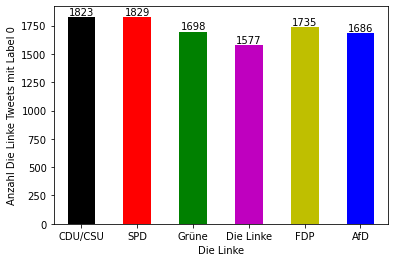

In [ ]:
# bar chart of die linke label 0 klassifikation
ax = die_linke.sum().plot.bar(rot=0, color=('k','r', 'g', 'm', 'y','b'))
ax.set(xlabel="Die Linke", ylabel='Anzahl Die Linke Tweets mit Label 0')
ax.bar_label(ax.containers[0])

In [ ]:
fdp = pd.read_csv('final_df_labeled_pol_tweets.csv')
fdp = fdp.loc[fdp['Party'] == 'FDP']
fdp = fdp.loc[fdp['Predicted Label'] == 0]

# creating conditions: the party has to be FDP and contain one of the 6 textlabel as well as the label 0, if these conditions are met
# a new column with the corresponding party according to the textlabel will be created and given the value of 1
# the values of the new columns will be added up for each party of the column s and displayed in a bar chart

#condition 1
conditions = [
     (fdp['Party'].eq('FDP')) & (fdp['Clean Text'].str.startswith(r'cdu/csu:')) & (fdp['Predicted Label'].eq(0))]

choices = [1]

fdp['CDU/CSU'] = np.select(conditions, choices, default=0)

# creating new column based on condition
fdp = fdp[['Party', 'Clean Text', 'Predicted Label', 'CDU/CSU']]

#condition 2
conditions = [
     (fdp['Party'].eq('FDP')) & (fdp['Clean Text'].str.startswith(r'spd:')) & (fdp['Predicted Label'].eq(0))]

choices = [1]

fdp['SPD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
fdp = fdp[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD']]

#condition 3
conditions = [
     (fdp['Party'].eq('FDP')) & (fdp['Clean Text'].str.startswith(r'grüne:')) & (fdp['Predicted Label'].eq(0))]

choices = [1]

fdp['Grüne'] = np.select(conditions, choices, default=0)

# creating new column based on condition
fdp = fdp[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne']]

#condition 4
conditions = [
     (fdp['Party'].eq('FDP')) & (fdp['Clean Text'].str.startswith(r'die linke:')) & (fdp['Predicted Label'].eq(0))]

choices = [1]

fdp['Die Linke'] = np.select(conditions, choices, default=0)

# creating new column based on condition
fdp = fdp[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke']]

#condition 5
conditions = [
     (fdp['Party'].eq('FDP')) & (fdp['Clean Text'].str.startswith(r'fdp:')) & (fdp['Predicted Label'].eq(0))]

choices = [1]

fdp['FDP'] = np.select(conditions, choices, default=0)

# creating new column based on condition
fdp = fdp[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP']]

#condition 6
conditions = [
     (fdp['Party'].eq('FDP')) & (fdp['Clean Text'].str.startswith(r'afd:')) & (fdp['Predicted Label'].eq(0))]

choices = [1]

fdp['AfD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
fdp = fdp[['CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP', 'AfD']]

In [ ]:
fdp.shape

(20924, 6)

[Text(0, 0, '3752'),
 Text(0, 0, '3638'),
 Text(0, 0, '3391'),
 Text(0, 0, '3101'),
 Text(0, 0, '3607'),
 Text(0, 0, '3435')]

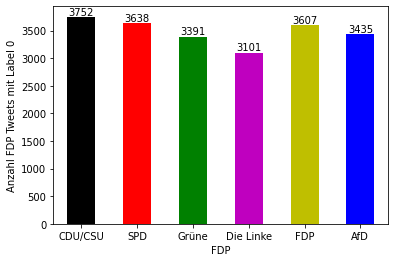

In [ ]:
# bar chart of fdp label 0 klassifikation
ax = fdp.sum().plot.bar(rot=0, color=('k','r', 'g', 'm', 'y','b'))
ax.set(xlabel="FDP", ylabel='Anzahl FDP Tweets mit Label 0')
ax.bar_label(ax.containers[0])

In [ ]:
afd = pd.read_csv('final_df_labeled_pol_tweets.csv')
afd = afd.loc[afd['Party'] == 'AfD']
afd = afd.loc[afd['Predicted Label'] == 0]

# creating conditions: the party has to be afd and contain one of the 6 textlabel as well as the label 0, if these conditions are met
# a new column with the corresponding party according to the textlabel will be created and given the value of 1
# the values of the new columns will be added up for each party of the column s and displayed in a bar chart

#condition 1
conditions = [
     (afd['Party'].eq('AfD')) & (afd['Clean Text'].str.startswith(r'cdu/csu:')) & (afd['Predicted Label'].eq(0))]

choices = [1]

afd['CDU/CSU'] = np.select(conditions, choices, default=0)

# creating new column based on condition
afd = afd[['Party', 'Clean Text', 'Predicted Label', 'CDU/CSU']]

#condition 2
conditions = [
     (afd['Party'].eq('AfD')) & (afd['Clean Text'].str.startswith(r'spd:')) & (afd['Predicted Label'].eq(0))]

choices = [1]

afd['SPD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
afd = afd[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD']]

#condition 3
conditions = [
     (afd['Party'].eq('AfD')) & (afd['Clean Text'].str.startswith(r'grüne:')) & (afd['Predicted Label'].eq(0))]

choices = [1]

afd['Grüne'] = np.select(conditions, choices, default=0)

# creating new column based on condition
afd = afd[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne']]

#condition 4
conditions = [
     (afd['Party'].eq('AfD')) & (afd['Clean Text'].str.startswith(r'die linke:')) & (afd['Predicted Label'].eq(0))]

choices = [1]

afd['Die Linke'] = np.select(conditions, choices, default=0)

# creating new column based on condition
afd = afd[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke']]

#condition 5
conditions = [
     (afd['Party'].eq('AfD')) & (afd['Clean Text'].str.startswith(r'fdp:')) & (afd['Predicted Label'].eq(0))]

choices = [1]

afd['FDP'] = np.select(conditions, choices, default=0)

# creating new column based on condition
afd = afd[['Party', 'Clean Text', 'Predicted Label','CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP']]

#condition 6
conditions = [
     (afd['Party'].eq('AfD')) & (afd['Clean Text'].str.startswith(r'afd:')) & (afd['Predicted Label'].eq(0))]

choices = [1]

afd['AfD'] = np.select(conditions, choices, default=0)

# creating new column based on condition
afd = afd[['CDU/CSU', 'SPD', 'Grüne', 'Die Linke', 'FDP', 'AfD']]

In [ ]:
afd.shape

(12423, 6)

[Text(0, 0, '2267'),
 Text(0, 0, '2191'),
 Text(0, 0, '1955'),
 Text(0, 0, '1740'),
 Text(0, 0, '2108'),
 Text(0, 0, '2162')]

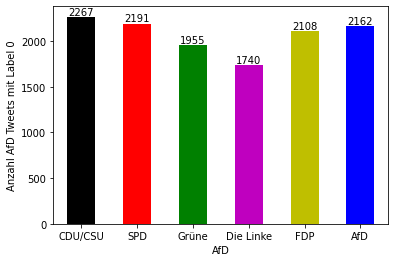

In [ ]:
# bar chart of fdp label 0 klassifikation
ax = afd.sum().plot.bar(rot=0, color=('k','r', 'g', 'm', 'y','b'))
ax.set(xlabel="AfD", ylabel='Anzahl AfD Tweets mit Label 0')
ax.bar_label(ax.containers[0])

# **Wordclouds**
- Wordcloud für alle Parteien
- Wordclouds je Partei

In [20]:
# creating a dataframe for each party which will be used to create a party specific wordcloud
# cdu/csu
df1 = pd.read_csv('clean_tweets_df.csv')
cdu_csu = df1.loc[df1['Party'] == 'CDU/CSU']
cdu_csu.to_csv('cdu_csu_party.csv')

# spd
df1 = pd.read_csv('clean_tweets_df.csv')
spd = df1.loc[df1['Party'] == 'SPD']
spd.to_csv('spd_party.csv')

# grüne
df1 = pd.read_csv('clean_tweets_df.csv')
grüne = df1.loc[df1['Party'] == 'Grüne']
grüne.to_csv('grüne_party.csv')

#die linke
df1 = pd.read_csv('clean_tweets_df.csv')
die_linke = df1.loc[df1['Party'] == 'Linke']
die_linke.to_csv('die_linke_party.csv')

# fdp
df1 = pd.read_csv('clean_tweets_df.csv')
fdp = df1.loc[df1['Party'] == 'FDP']
fdp.to_csv('fdp_party.csv')

#afd
df1 = pd.read_csv('clean_tweets_df.csv')
df1.loc[df1['Party'] == 'AfD']
df1.to_csv('afd_party.csv')

In [22]:
# wordcloud of the most used terms by political parties
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


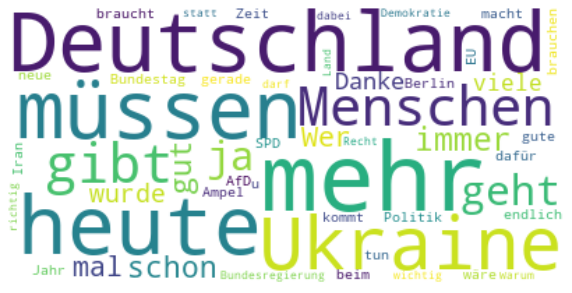

In [49]:
# wordcloud of trending words and topics in politics over all parties
df1 = pd.read_csv('clean_tweets_df.csv')

# stop words removal otherwise the stop words would dominate the wordclous
german_stop_words = stopwords.words('german')

wordcloud_text = df1['Clean Text']
wordcloud_text_to_list = df1['Clean Text'].values.tolist()
wordcloud_text_list = " ".join(wordcloud_text_to_list)

wordcloud = WordCloud(stopwords=german_stop_words, background_color="white", max_words=50).generate(wordcloud_text_list)

plt.figure(figsize=(10,10))
plt.axis("off")
plt.imshow(wordcloud, interpolation="bilinear")
plt.show()

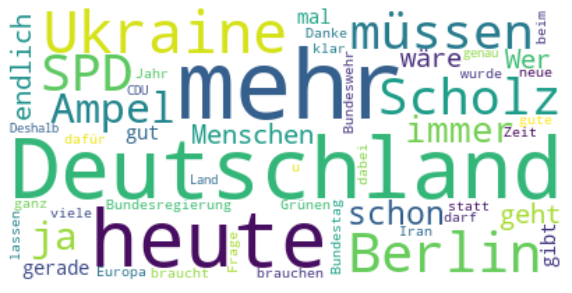

In [48]:
# wordcloud of trending words and topics for party cdu/csu
cdu_csu = pd.read_csv('cdu_csu_party.csv')

# stop words removal otherwise the stop words would dominate the wordclous
german_stop_words = stopwords.words('german')

wordcloud_text = cdu_csu['Clean Text']
wordcloud_text_to_list = cdu_csu['Clean Text'].values.tolist()
wordcloud_text_list = " ".join(wordcloud_text_to_list)

wordcloud = WordCloud(stopwords=german_stop_words, background_color="white", max_words=50).generate(wordcloud_text_list)

plt.figure(figsize=(10,10))
plt.axis("off")
plt.imshow(wordcloud, interpolation="bilinear")
plt.show()

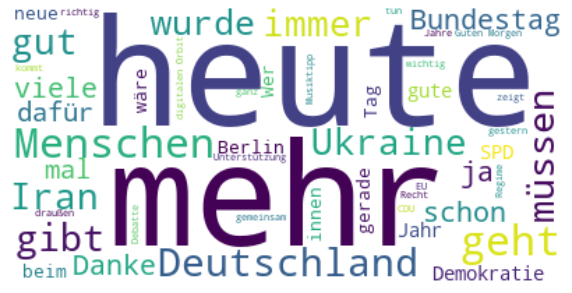

In [43]:
# wordcloud of trending words and topics for party spd
spd= pd.read_csv('spd_party.csv')

# stop words removal otherwise the stop words would dominate the wordclous
german_stop_words = stopwords.words('german')

wordcloud_text = spd['Clean Text']
wordcloud_text_to_list = spd['Clean Text'].values.tolist()
wordcloud_text_list = " ".join(wordcloud_text_to_list)

wordcloud = WordCloud(stopwords=german_stop_words, background_color="white", max_words=50).generate(wordcloud_text_list)

plt.figure(figsize=(10,10))
plt.axis("off")
plt.imshow(wordcloud, interpolation="bilinear")
plt.show()

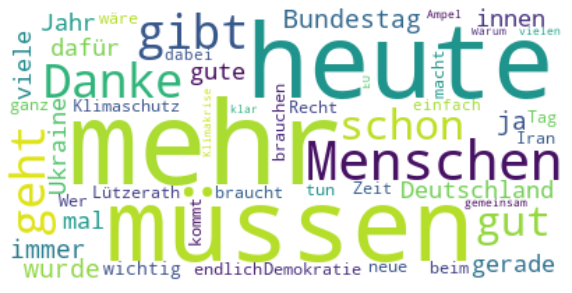

In [44]:
# wordcloud of trending words and topics for party grüne
grüne = pd.read_csv('grüne_party.csv')

# stop words removal otherwise the stop words would dominate the wordclous
german_stop_words = stopwords.words('german')

wordcloud_text = grüne['Clean Text']
wordcloud_text_to_list = grüne['Clean Text'].values.tolist()
wordcloud_text_list = " ".join(wordcloud_text_to_list)

wordcloud = WordCloud(stopwords=german_stop_words, background_color="white", max_words=50).generate(wordcloud_text_list)

plt.figure(figsize=(10,10))
plt.axis("off")
plt.imshow(wordcloud, interpolation="bilinear")
plt.show()

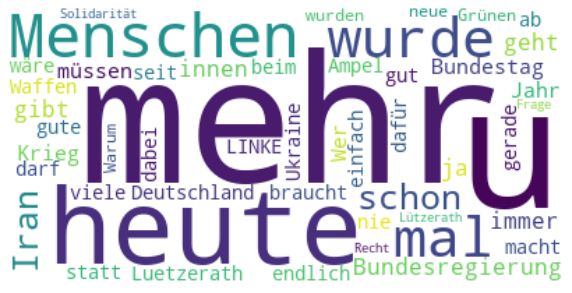

In [45]:
# wordcloud of trending words and topics for party die linke
die_linke = pd.read_csv('die_linke_party.csv')

# stop words removal otherwise the stop words would dominate the wordclous
german_stop_words = stopwords.words('german')

wordcloud_text = die_linke['Clean Text']
wordcloud_text_to_list = die_linke['Clean Text'].values.tolist()
wordcloud_text_list = " ".join(wordcloud_text_to_list)

wordcloud = WordCloud(stopwords=german_stop_words, background_color="white", max_words=50).generate(wordcloud_text_list)

plt.figure(figsize=(10,10))
plt.axis("off")
plt.imshow(wordcloud, interpolation="bilinear")
plt.show()

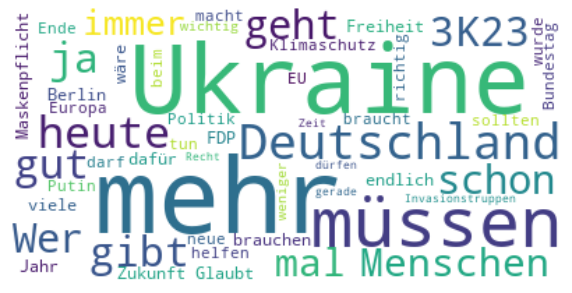

In [46]:
# wordcloud of trending words and topics for party fdp
fdp = pd.read_csv('fdp_party.csv')

# stop words removal otherwise the stop words would dominate the wordclous
german_stop_words = stopwords.words('german')

wordcloud_text = fdp['Clean Text']
wordcloud_text_to_list = fdp['Clean Text'].values.tolist()
wordcloud_text_list = " ".join(wordcloud_text_to_list)

wordcloud = WordCloud(stopwords=german_stop_words, background_color="white", max_words=50).generate(wordcloud_text_list)

plt.figure( figsize=(10,10))
plt.axis("off")
plt.imshow(wordcloud, interpolation="bilinear")
plt.show()

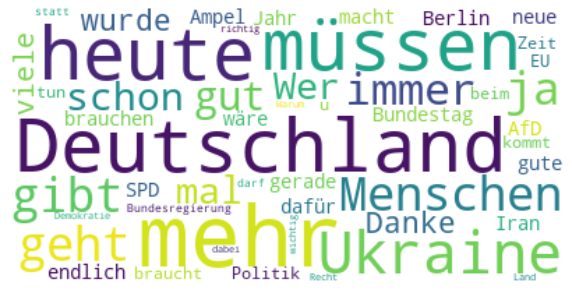

In [47]:
# wordcloud of trending words and topics for party fafd
afd = pd.read_csv('afd_party.csv')

# stop words removal otherwise the stop words would dominate the wordclous
german_stop_words = stopwords.words('german')

wordcloud_text = afd['Clean Text']
wordcloud_text_to_list = afd['Clean Text'].values.tolist()
wordcloud_text_list = " ".join(wordcloud_text_to_list)

wordcloud = WordCloud(stopwords=german_stop_words, background_color="white", max_words=50).generate(wordcloud_text_list)

plt.figure( figsize=(10,10))
plt.axis("off")
plt.imshow(wordcloud, interpolation="bilinear")
plt.show()